In [29]:
#Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [2]:
data = 'https://raw.githubusercontent.com/Javier-Gutierrez/machine-learning-zoomcamp/refs/heads/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [3]:
df = pd.read_csv(data)

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
#checking the general informacion of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [5]:
df.nunique()

lead_source                    5
industry                       6
employment_status              4
location                       5
annual_income               4313
number_of_courses_viewed       7
interaction_count             14
lead_score                    99
converted                      2
dtype: int64

In [6]:
#Checking for columns with missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [7]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='object')

In [8]:
#Categorical

categorical = ['lead_source', 'industry', 'employment_status', 'location','converted']

In [9]:
#Numerical

numerical =  ['annual_income', 'number_of_courses_viewed', 'interaction_count','lead_score']

In [10]:
#Filling categorical missing values

for col in categorical:
    df[col] = df[col].fillna('NA')

print(df.isnull().sum())

lead_source                   0
industry                      0
employment_status             0
location                      0
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [11]:
#Filling numerical missing values

for col in numerical:
    df[col] = df[col].fillna(0)

print(df.isnull().sum())

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [12]:
#Q1 seeing the mode in column industry

df.industry.mode()

0    technology
Name: industry, dtype: object

In [13]:
#Looking at the correlation beetwen variables

corr_matrix = df[numerical].corr()

corr_matrix

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000


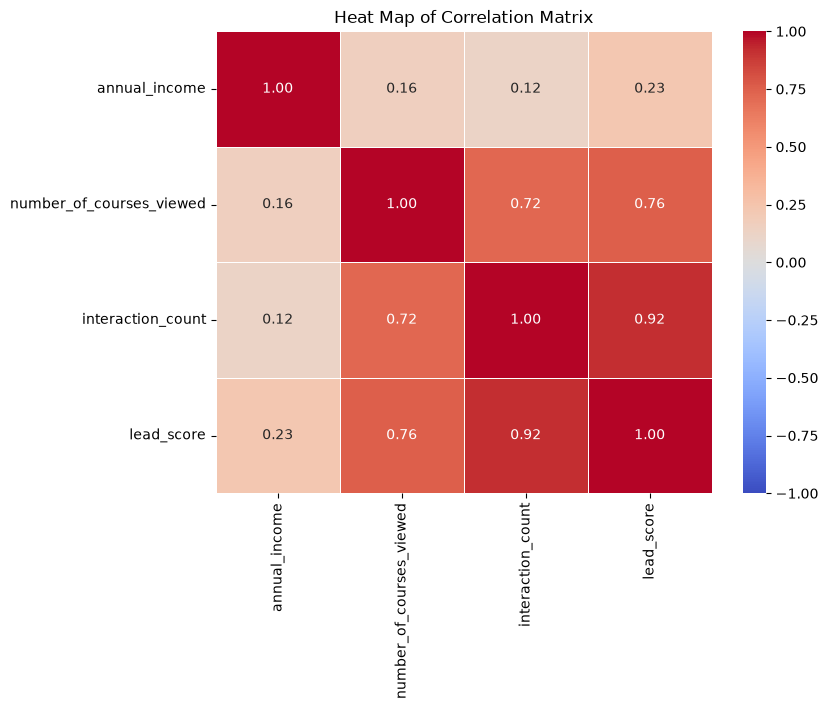

In [14]:
#Visalization of corr matrix

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Heat Map of Correlation Matrix')
plt.show()

In [15]:
#Splitting the dataset
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

In [16]:
#Reseting index

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [17]:
#Spliting the target

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [18]:
y_train

array([1, 0, 1, ..., 1, 0, 0], shape=(3000,))

In [19]:
#Checking the converted rate

df_full_train.converted.value_counts(normalize=True)

converted
1    0.57075
0    0.42925
Name: proportion, dtype: float64

In [20]:
#Q3 Mutual information, without considering converted column

def mutual_info_converted_score(series):
    return mutual_info_score(series, df_full_train.converted)
mi = df_full_train[categorical].apply(mutual_info_converted_score)
round(mi.sort_values(ascending=False),2)



converted            0.68
lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

In [21]:
#Deleting the target from my datasets for avoiding problems

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [ ]:
#Q4
#Making One-hot encoding of train dataset

#Train dataset
train_dicts = df_train.to_dict(orient='records')
#Genereting and instance for Vectorizer
dv_train = DictVectorizer(sparse=False)
X_train = dv_train.fit_transform(train_dicts)

#Validation dataset
val_dicts = df_val.to_dict(orient='records')
dv_val = DictVectorizer(sparse=False)
X_val = dv_val.fit_transform(val_dicts)

In [31]:
#Logistic regression

#Instance for logistic regression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The 

In [ ]:
#prediction

y_pred = model.predict(X_val)
y_pred

In [ ]:
y_val

In [56]:
#Let's see accuracy

(y_val == y_pred).mean()



np.float64(0.645)

In [ ]:
#Q5
#Smaller datasets

#Df for train
df_train_wo_lead = df_train.drop(columns=['lead_source'])
df_train_wo_courses = df_train.drop(columns=['number_of_courses_viewed'])
df_train_wo_interaction =  df_train.drop(columns=['interaction_count'])

#Df for validation
df_val_wo_lead = df_val.drop(columns=['lead_source'])
df_val_wo_courses = df_val.drop(columns=['number_of_courses_viewed'])
df_val_wo_interaction =  df_val.drop(columns=['interaction_count'])

In [ ]:
#Making One-hot encoding of train without lead sorce 

#Train dataset
train_dicts_wo_lead = df_train_wo_lead.to_dict(orient='records')
#Genereting and instance for Vectorizer
dv_train_wo_lead = DictVectorizer(sparse=False)
X_train_wo_lead = dv_train_wo_lead.fit_transform(train_dicts_wo_lead)

#Validation dataset
val_dicts_wo_lead = df_val_wo_lead.to_dict(orient='records')
dv_val_wo_lead = DictVectorizer(sparse=False)
X_val_wo_lead = dv_val_wo_lead.fit_transform(val_dicts_wo_lead)

In [49]:
#Making One-hot encoding of train without Courses viewed

#Train dataset
train_dicts_wo_courses = df_train_wo_courses.to_dict(orient='records')
#Genereting and instance for Vectorizer
dv_train_wo_courses = DictVectorizer(sparse=False)
X_train_wo_courses = dv_train_wo_courses.fit_transform(train_dicts_wo_courses)

#Validation dataset
val_dicts_wo_courses = df_val_wo_courses.to_dict(orient='records')
dv_val_wo_courses = DictVectorizer(sparse=False)
X_val_wo_courses = dv_val_wo_courses.fit_transform(val_dicts_wo_courses)

In [51]:
#Making One-hot encoding of train without Interaction cont

#Train dataset
train_dicts_wo_interaction = df_train_wo_interaction.to_dict(orient='records')
#Genereting and instance for Vectorizer
dv_train_wo_interaction = DictVectorizer(sparse=False)
X_train_wo_interaction = dv_train_wo_interaction.fit_transform(train_dicts_wo_interaction)

#Validation dataset
val_dicts_wo_interaction = df_val_wo_interaction.to_dict(orient='records')
dv_val_wo_interaction = DictVectorizer(sparse=False)
X_val_wo_interaction = dv_val_wo_interaction.fit_transform(val_dicts_wo_interaction)

In [54]:
#Logistic regression without lead source

#Instance for logistic regression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train_wo_lead, y_train)

#prediction
y_pred_wo_lead = model.predict(X_val_wo_lead)

#Let's see accuracy
(y_val == y_pred_wo_lead).mean()

np.float64(0.642)

In [55]:
#Logistic regression without lead courses viewed

#Instance for logistic regression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train_wo_courses, y_train)

#prediction
y_pred_wo_courses = model.predict(X_val_wo_courses)

#Let's see accuracy
(y_val == y_pred_wo_courses).mean()

np.float64(0.643)

In [57]:
#Logistic regression without lead interaction count

#Instance for logistic regression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train_wo_interaction, y_train)

#prediction
y_pred_wo_interaction = model.predict(X_val_wo_interaction)

#Let's see accuracy
(y_val == y_pred_wo_interaction).mean()

np.float64(0.601)

In [63]:
#Q6 Regularized logistic regression

#Making One-hot encoding of train dataset

reg= [0.000001, 0.00001, 0.0001, 0.001]

#Train dataset
train_dicts = df_train.to_dict(orient='records')
#Genereting and instance for Vectorizer
dv_train = DictVectorizer(sparse=False)
X_train = dv_train.fit_transform(train_dicts)

#Validation dataset
val_dicts = df_val.to_dict(orient='records')
dv_val = DictVectorizer(sparse=False)
X_val = dv_val.fit_transform(val_dicts)

for regu in reg:
    #Instance for logistic regression
    
    model = LogisticRegression(solver='liblinear', C=regu, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)
    y_pred

    #Let's see accuracy

    print(round((y_val == y_pred).mean(),3))


0.598
0.598
0.613
0.645
